# ESM1b pathogenicity and observed variation in 30 large-pore channel genes

**CancerLetters • Unified Figure 5 and Figures S5–S7 workflow**

## Choose the task

1. **Reproduce existing figures now:** keep `MODE = "snapshot"`. Figure 5 is reconstructed from digitized bars/reference lines. S5–S7 are recalculated from archived mutation records and the **historically digitized** All SNV fractions used in the earlier correlations. Nothing here presents digitized fractions as raw model predictions.
2. **Estimate fractions from your ESM files:** set `MODE = "recompute"`, copy one CSV-format `.esm` file per gene into `data/ESMs/`, provide matching CDS/protein FASTA or enable sequence retrieval, then run all cells. No `HUMAN.map` is required. The expected filenames are in `data/esm_inputs.tsv` and can be edited, including for OMA/UniProt filenames.

### Outputs

`outputs/Figure5.{png,pdf}`, `S5.{png,pdf}`, `S6.{png,pdf}`, `S7.{png,pdf}`; per-gene tables, statistics, captions, input checksums, and a run manifest. Large datasets stay under `data/`, outside notebook cells. The complete bundle is portable: unzip it and open this notebook from its folder.

## 1. Environment and configuration

Create the lightweight plotting/analysis environment with `conda env create -f environment.yml`, then `conda activate lpc_esm`. Optional ESM inference uses the upstream `ntranoslab/esm-variants` script in a separate torch/fair-esm environment; cached scores are preferred. Online retrieval is opt-in and writes to a separate cache, leaving archived data unchanged.

In [1]:
from pathlib import Path
import sys, json, hashlib, platform, re, subprocess, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize, FuncNorm
from scipy import stats
from Bio import SeqIO
from Bio.Seq import Seq
from IPython.display import display, Markdown

# Change ROOT only if you launch Jupyter from another working directory.
ROOT = Path.cwd()
assert (ROOT / "data/gene_manifest.tsv").exists(), "Open this notebook from the unzipped LPC_unified folder."
DATA, OUT = ROOT / "data", ROOT / "outputs"
OUT.mkdir(exist_ok=True)
MODE = "snapshot"                       # "snapshot" or "recompute"
ESM_DIR = DATA / "ESMs"                 # one CSV-format *.esm per gene
ALLOW_SEQUENCE_DOWNLOAD = False          # opt in only when matched local sequences are absent
RUN_ESM_INFERENCE = False                # optional: generate missing score files with upstream script
ESM_SCRIPT = ROOT / "external/esm-variants/esm_score_missense_mutations.py"
ESM_PYTHON = sys.executable               # point to your torch/fair-esm Python if needed
THRESHOLD = -7.5                         # historical ESM1b LLR threshold, inclusive
COUNTING = "legacy"                     # "legacy" reproduces latest supplied notebook
CONTROL_CI = "actual_n"                 # or "legacy_n30" to reproduce its hard-coded sqrt(30)
USE_RECOMPUTED_X = True                  # applied only in recompute mode; updates S5 and S7 too
SEED = 20261122
assert MODE in {"snapshot", "recompute"}
assert COUNTING in {"legacy", "comparable_missense"}
assert CONTROL_CI in {"actual_n", "legacy_n30"}
plt.rcParams.update({"font.family":"DejaVu Sans", "pdf.fonttype":42,
                     "font.size":10, "axes.spines.top":False, "axes.spines.right":False})

def save_figure(fig, name):
    # Export vector PDF and publication-resolution PNG from the same figure.
    for ext in ("png", "pdf"):
        fig.savefig(OUT / f"{name}.{ext}", dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()

## 2. Fixed panel, transcripts, and input provenance

Exactly 30 genes are required. `gene_manifest.tsv` preserves the Ensembl gene spans/protein lengths and the gnomAD transcripts used in the previous analysis. Those lengths colour S5/S7; they are not silently replaced by a different ESM isoform's length. `esm_inputs.tsv` is an editable input manifest: gene, score filename, expected sequence ID, CDS FASTA and optional protein FASTA. Blank `seq_id` accepts a **single** sequence ID per score file; multiple proteins require explicit selection.

A full-human score file can also be referenced by several manifest rows with different `seq_id` values; data are read in chunks and only the selected sequence is retained.

In [2]:
GENES = [f"CALHM{i}" for i in range(1,7)] + ["GJA1","GJA3","GJA4","GJA5","GJA8","GJA9","GJA10"] + [f"GJB{i}" for i in range(1,8)] + ["GJC1","GJC2","GJC3","GJD2","GJD3","GJD4","GJE1","PANX1","PANX2","PANX3"]
TISSUES = ["Bladder","Brain","Breast","Colorectal","Esophagus","Kidney","Liver","Lung","Ovary","Prostate","Skin","Uterus"]
manifest = pd.read_csv(DATA / "gene_manifest.tsv", sep="\t").set_index("gene").loc[GENES]
esm_inputs = pd.read_csv(DATA / "esm_inputs.tsv", sep="\t", keep_default_na=False).set_index("gene")
assert len(GENES) == len(set(GENES)) == 30
assert set(manifest.index) == set(esm_inputs.index) == set(GENES)
assert (manifest.gene_span_bp > 0).all() and (manifest.protein_length_aa > 0).all()
assert (manifest.end_1based - manifest.start_1based + 1).equals(manifest.gene_span_bp)
display(manifest[["ensembl_gene_id","ensembl_transcript_id","gnomad_transcript_id","protein_length_aa","gene_span_bp"]])

,ensembl_gene_id,ensembl_transcript_id,gnomad_transcript_id,protein_length_aa,gene_span_bp
gene,,,,,
CALHM1,ENSG00000185933,ENST00000329905,ENST00000329905,346,5661
CALHM2,ENSG00000138172,ENST00000260743,ENST00000260743,323,6004
CALHM3,ENSG00000183128,ENST00000369783,ENST00000369783,344,6437
CALHM4,ENSG00000164451,ENST00000368596,ENST00000368596,314,32115
CALHM5,ENSG00000178033,ENST00000368599,ENST00000368599,309,13185
CALHM6,ENSG00000188820,ENST00000368605,ENST00000368605,315,4718
GJA1,ENSG00000152661,ENST00000282561,ENST00000282561,382,14163
GJA3,ENSG00000121743,ENST00000241125,ENST00000241125,435,23364
GJA4,ENSG00000187513,ENST00000342280,ENST00000342280,333,2765


## 3. What the ESM fraction means—and what the ROS signature counts

ESM1b assigns the log-likelihood ratio of a mutant versus reference amino acid. Scores **≤ −7.5** are labelled predicted pathogenic/deleterious for this analysis; they are not calibrated clinical probabilities or evidence that the gene causes cancer.

The latest supplied notebook is authoritative for Figure 5:

* **All SNV:** enumerate all nine nucleotide substitutions per codon, retain distinct non-reference amino-acid outcomes, join to ESM scores, and count each amino-acid change once per site. Synonymous outcomes are excluded. Stop outcomes lack missense ESM scores and were silently skipped; we report their count explicitly. This is a fraction of **SNV-accessible missense changes**, not all nucleotide mutations.
* **ROS:** scan the concatenated coding sequence for the 11 declared triplet replacements, including across codon boundaries. Match enumeration preserves Python `str.split()`'s non-overlapping occurrences. Every event contributes once; synonymous outcomes count as neutral; stop-generating outcomes count as deleterious without an ESM score. Missense events use the same −7.5 threshold. No reverse complements or frequency weights are added: this preserves the provided code, rather than redefining it as COSMIC SBS18/SBS36.
* **Comparable missense sensitivity:** optionally restrict both panels to unique, scoreable missense outcomes. This removes the legacy denominator asymmetry but is a new sensitivity analysis, not an exact recreation of Figure 5.


In [3]:
ROS_TRIPLETS = {"TCT":"TAT", "GCA":"GAA", "CCA":"CAA", "TCA":"TAA", "GCT":"GAT",
                "ACA":"AAA", "TCC":"TAC", "CCT":"CAT", "ACT":"AAT", "CCC":"CAC", "GCC":"GAC"}
AA20 = set("ACDEFGHIKLMNPQRSTVWY")

def read_one_fasta(path):
    records = list(SeqIO.parse(path, "fasta"))
    if len(records) != 1:
        raise ValueError(f"Expected one sequence in {path}; found {len(records)}")
    return str(records[0].seq).upper()

def load_esm(path, seq_id=""):
    # Native upstream schema is seq_id, mut_name (e.g. M1A), esm_score.
    selected = []; seen_ids = set()
    for chunk in pd.read_csv(path, chunksize=100000):
        if not {"seq_id","mut_name","esm_score"}.issubset(chunk.columns):
            raise ValueError(f"{path}: expected seq_id, mut_name, esm_score")
        chunk.seq_id = chunk.seq_id.astype(str)
        seen_ids.update(chunk.seq_id.unique())
        selected.append(chunk[chunk.seq_id.eq(seq_id)] if seq_id else chunk)
    if not seq_id and len(seen_ids) != 1:
        raise ValueError(f"{path}: specify seq_id; found {len(seen_ids)} sequence IDs")
    d = pd.concat(selected, ignore_index=True)
    if d.empty: raise ValueError(f"No scores selected from {path}")
    parsed = d.mut_name.str.extract(r"^([A-Z])(\d+)([A-Z])$")
    if parsed.isna().any().any(): raise ValueError("Unsupported mutation notation")
    d[["ref","pos","alt"]] = parsed
    d.pos = d.pos.astype(int); d.esm_score = pd.to_numeric(d.esm_score, errors="raise")
    if not np.isfinite(d.esm_score).all(): raise ValueError("Non-finite ESM score")
    if d.duplicated(["pos","ref","alt"]).any(): raise ValueError("Duplicate ESM score key")
    if (d.groupby("pos").ref.nunique() != 1).any(): raise ValueError("Conflicting reference residues")
    return d

def get_sequences(row):
    cds_path = DATA / row.cds_file
    if not cds_path.exists():
        if not ALLOW_SEQUENCE_DOWNLOAD:
            raise FileNotFoundError(f"Supply {cds_path}, or enable ALLOW_SEQUENCE_DOWNLOAD. Use CDS, not cDNA.")
        import requests
        from requests.adapters import HTTPAdapter
        from urllib3.util.retry import Retry
        session=requests.Session()
        session.mount("https://",HTTPAdapter(max_retries=Retry(total=5,backoff_factor=1,status_forcelist=[429,500,502,503,504])))
        # Transcript is explicit: no arbitrary first-isoform selection.
        tx = row.transcript_id
        url = f"https://rest.ensembl.org/sequence/id/{tx}"
        response = session.get(url, params={"type":"cds"}, headers={"Accept":"text/plain"}, timeout=90)
        response.raise_for_status(); cds = response.text.strip().upper()
        if not set(cds) <= set("ACGT"): raise ValueError("Ensembl response is not unambiguous CDS")
        cds_path.parent.mkdir(parents=True, exist_ok=True)
        cds_path.write_text(f">{tx}\n{cds}\n")
        (cds_path.with_suffix(".provenance.json")).write_text(json.dumps({"url":response.url,"retrieved_utc":time.strftime("%Y-%m-%dT%H:%M:%SZ",time.gmtime())}, indent=2))
    cds = read_one_fasta(cds_path)
    if len(cds)%3 or not set(cds)<=set("ACGT"): raise ValueError(f"Invalid CDS in {cds_path}")
    protein = str(Seq(cds).translate())
    if protein.endswith("*"): cds, protein = cds[:-3], protein[:-1]
    if not protein or not set(protein) <= AA20: raise ValueError("Internal stop/ambiguous protein")
    if row.protein_file:
        if read_one_fasta(DATA / row.protein_file) != protein:
            raise ValueError("Supplied protein and translated CDS differ")
    return cds, protein

def check_scores(d, protein):
    # ESM files must cover the whole reference sequence, even if some mutations are not SNV-accessible.
    refs = d.groupby("pos").ref.first()
    if set(refs.index) != set(range(1,len(protein)+1)):
        raise ValueError("ESM positions and CDS protein length differ")
    if ''.join(refs.sort_index()) != protein:
        raise ValueError("ESM reference protein differs from CDS translation: choose the matched isoform")
    return {(r.pos,r.ref,r.alt):r.esm_score for r in d.itertuples() if r.ref != r.alt}

def score_outcomes(cds, protein, scores, counting="legacy"):
    records=[]; excluded_stops=0
    def score(ref, pos, alt):
        key=(pos,ref,alt)
        if key not in scores: raise ValueError(f"Missing missense ESM score {ref}{pos}{alt}")
        return scores[key]
    # Use a set to reproduce unique AA outcomes per codon for All SNV.
    for i in range(len(protein)):
        codon=cds[3*i:3*i+3]; alts=set()
        for offset in range(3):
            for base in "ACGT":
                if base != codon[offset]:
                    alts.add(str(Seq(codon[:offset]+base+codon[offset+1:]).translate()))
        for alt in sorted(alts-{protein[i]}):
            if alt == "*": excluded_stops += 1; continue
            value=score(protein[i],i+1,alt)
            records.append(dict(category="All SNV",pos=i+1,ref=protein[i],alt=alt,kind="missense",esm_score=value,pathogenic=value<=THRESHOLD))
    # str.split retains non-overlapping motif matches, as in snvs_ros_suppMat.ipynb.
    for motif, replacement in ROS_TRIPLETS.items():
        start=0
        while True:
            hit=cds.find(motif,start)
            if hit<0: break
            start=hit+len(motif)
            nt=hit+1; pos=nt//3+1; off=nt%3
            codon=cds[(pos-1)*3:pos*3]
            mutant=codon[:off]+replacement[1]+codon[off+1:]
            ref=protein[pos-1]; alt=str(Seq(mutant).translate())
            kind="stop_gain" if alt=="*" else "synonymous" if alt==ref else "missense"
            value=score(ref,pos,alt) if kind=="missense" else np.nan
            path=kind=="stop_gain" or (kind=="missense" and value<=THRESHOLD)
            records.append(dict(category="ROS",pos=pos,ref=ref,alt=alt,kind=kind,esm_score=value,pathogenic=bool(path)))
    events=pd.DataFrame(records)
    if counting=="comparable_missense":
        events=events[events.kind.eq("missense")].drop_duplicates(["category","pos","ref","alt"])
    summary=events.groupby("category").agg(n_total=("pathogenic","size"),n_pathogenic=("pathogenic","sum"))
    summary["fraction"]=summary.n_pathogenic/summary.n_total
    summary["all_snv_unscored_stop_outcomes"]=excluded_stops
    if set(summary.index)!={"All SNV","ROS"}: raise ValueError("Empty mutation category")
    return events,summary.reset_index()

## 4. Optional ESM inference, then per-gene fractions

The default input is your existing ESM folder. Inference is optional, uses checked subprocess return codes, and does not download/execute scripts automatically. Install the upstream repository yourself and set `ESM_SCRIPT`. The `.esm` CSV schema is `seq_id,mut_name,esm_score`. The model name is fixed to `esm1b_t33_650M_UR50S`.

For exact reproduction use the same OMA main-isoform protein/CDS pairs as Figure 5. The provided manifest starts with the previously used Ensembl canonical transcript IDs; these are candidates. Replace them or provide your matched CDS FASTA when validation fails.

In [4]:
if MODE == "recompute":
    ESM_DIR.mkdir(exist_ok=True)
    fractions=[]; event_tables=[]; qc=[]
    for gene in GENES:
        row=esm_inputs.loc[gene]
        cds, protein=get_sequences(row)
        score_path=ESM_DIR / row.esm_file
        if not score_path.exists() and RUN_ESM_INFERENCE:
            if not ESM_SCRIPT.exists(): raise FileNotFoundError(ESM_SCRIPT)
            fasta=DATA / "sequences" / f"{gene}.inference.fasta"
            fasta.write_text(f">{row.seq_id or gene}\n{protein}\n")
            subprocess.run([ESM_PYTHON,str(ESM_SCRIPT),"--input-fasta-file",str(fasta),
                            "--output-csv-file",str(score_path),"--model-name","esm1b_t33_650M_UR50S"],check=True)
        if not score_path.exists(): raise FileNotFoundError(f"Supply ESM file: {score_path}")
        scored=load_esm(score_path,row.seq_id)
        scores=check_scores(scored,protein)
        events,summary=score_outcomes(cds,protein,scores,COUNTING)
        fractions.append(summary.assign(gene=gene,source=f"ESM1b; {COUNTING}; cutoff {THRESHOLD}"))
        event_tables.append(events.assign(gene=gene))
        qc.append(dict(gene=gene,esm_protein_length_aa=len(protein),cds_bp=len(cds),
                       archived_colour_length_aa=int(manifest.loc[gene,"protein_length_aa"]),
                       n_scores=len(scored),transcript=row.transcript_id))
    figure5=pd.concat(fractions,ignore_index=True)
    pd.concat(event_tables,ignore_index=True).to_csv(OUT/"esm_mutation_outcomes.tsv.gz",sep="\t",index=False)
    pd.DataFrame(qc).to_csv(OUT/"esm_sequence_qc.tsv",sep="\t",index=False)

figure5.to_csv(OUT/"Figure5_values.tsv",sep="\t",index=False)
display(figure5.head())

SNAPSHOT: Figure 5 fractions and control lines are image-derived approximations; no ESM inference performed.


,gene,category,figure_order,fraction,bar_top_pixel,bar_x_pixel,source
0,GJE1,All SNV,0,0.054545,365,65,Figure5.png digitization; approximate; not raw...
1,PANX2,All SNV,1,0.132468,315,86,Figure5.png digitization; approximate; not raw...
2,CALHM4,All SNV,2,0.157403,299,106,Figure5.png digitization; approximate; not raw...
3,CALHM3,All SNV,3,0.174545,288,127,Figure5.png digitization; approximate; not raw...
4,CALHM1,All SNV,4,0.179221,285,148,Figure5.png digitization; approximate; not raw...


## 5. Control means and Figure 5

For a recalculated analysis, supply `data/control_fractions.tsv` with columns `control_id,category,fraction` (one gene-level fraction per control/category, calculated using the same rules as the targets). The mean is unweighted across controls. We export the count and CI formula, avoiding the original unexplained hard-coded denominator. If controls are absent in recompute mode, reference lines are omitted rather than borrowing digitized ones.

Snapshot reference lines are digitized from the attachment. Their positions are reproducible; the absent control data do not allow us to verify their sampling design, mean, SD or confidence limits.

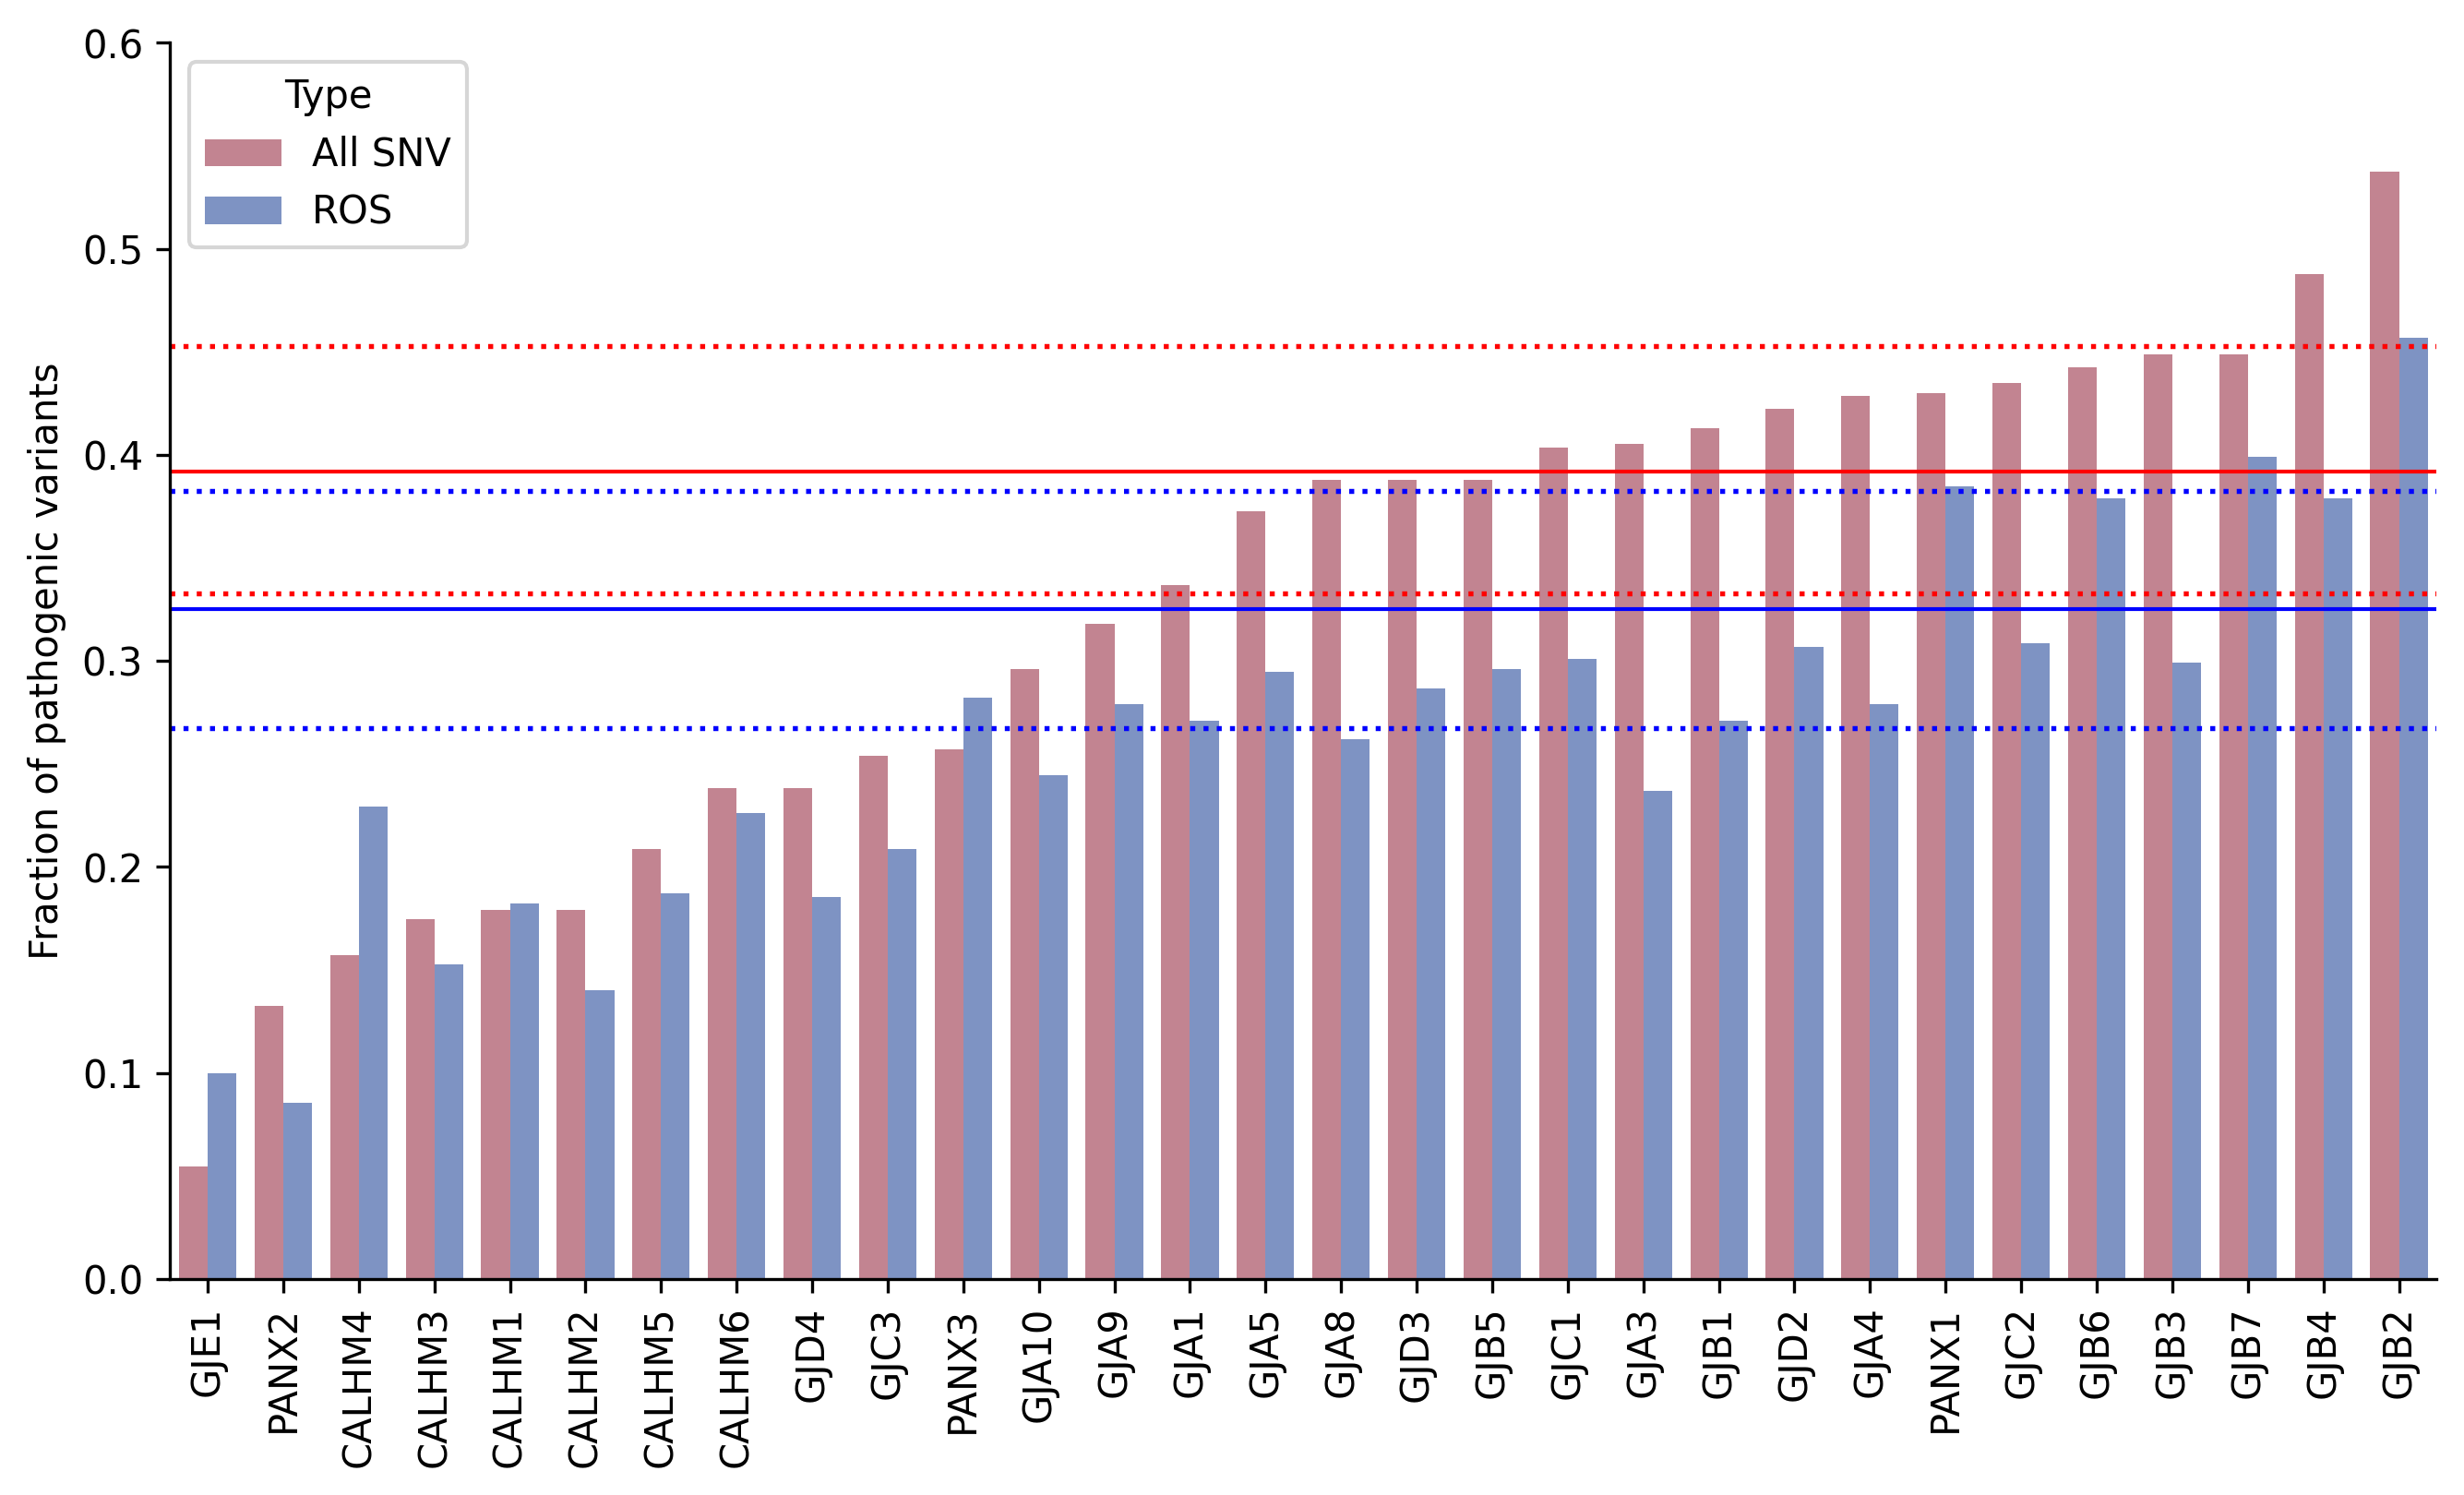

In [5]:
reference=[]
if MODE=="snapshot":
    lines=pd.read_csv(DATA/"figure5_reference_lines_digitized.tsv",sep="\t")
    for cat, group in lines.groupby("category"):
        vals=sorted(group.fraction)
        reference.append(dict(category=cat,mean=vals[1],lower=vals[0],upper=vals[2],n=np.nan,source="digitized reference lines"))
elif (DATA/"control_fractions.tsv").exists():
    controls=pd.read_csv(DATA/"control_fractions.tsv",sep="\t")
    assert not controls.duplicated(["control_id","category"]).any()
    assert controls.fraction.between(0,1).all()
    for cat, group in controls.groupby("category"):
        n=len(group)
        if n<2: raise ValueError("At least two controls required for an SD-based interval")
        denom=30 if CONTROL_CI=="legacy_n30" else n
        mean=group.fraction.mean(); half=1.96*group.fraction.std(ddof=1)/np.sqrt(denom)
        reference.append(dict(category=cat,mean=mean,lower=mean-half,upper=mean+half,n=n,source=CONTROL_CI))
else:
    print("No matched controls supplied: Figure 5 reference lines omitted.")
reference=pd.DataFrame(reference)
reference.to_csv(OUT/"Figure5_control_references.tsv",sep="\t",index=False)
# Stable sort preserves the historical tie order from the snapshot input.
order=figure5[figure5.category.eq("All SNV")].sort_values("fraction",kind="stable").gene.tolist()
pivot=figure5.pivot(index="gene",columns="category",values="fraction").loc[order]
assert pivot.shape==(30,2) and pivot.notna().all().all()
fig,ax=plt.subplots(figsize=(9,5.5)); x=np.arange(len(order)); width=.38
for dx,cat,col in [(-width/2,"All SNV","#c28491"),(width/2,"ROS","#7e93c3")]:
    ax.bar(x+dx,pivot[cat],width,label=cat,color=col)
for r in reference.itertuples():
    colour="red" if r.category=="All SNV" else "blue"
    ax.axhline(r.mean,color=colour,lw=1)
    ax.axhline(r.lower,color=colour,ls=":",lw=1.3)
    ax.axhline(r.upper,color=colour,ls=":",lw=1.3)
ax.set_xticks(x,order,rotation=90);ax.set_ylim(0,max(.6,float(pivot.max().max())+.04))
ax.set_ylabel("Fraction of pathogenic variants");ax.legend(title="Type",loc="upper left")
ax.margins(x=.004);fig.tight_layout();save_figure(fig,"Figure5")

## 6. COSMIC tissue counts from archived records (Fig S6)

Source: COSMIC v104, GRCh38, retrieved 4 October 2026. The accompanying annotated target export already contains the Classification/Sample metadata joins. We require `Confirmed somatic variant`; exclude explicitly labelled cell-line, organoid culture, short-term culture and xenograft specimens; and retain unspecified specimens. Primary-site tissue categories follow the original analysis (brain is specified CNS excluding spinal cord/NS; uterus is endometrium).

All retained mutation consequences, including indels, are eligible. Repeated transcript annotations collapse to one `(gene,tissue,COSMIC_SAMPLE_ID,GENOMIC_MUTATION_ID)` observation. A recurrent variant in two samples counts twice. These are counts of sample–variant observations, not mutation rates, independent patients, or sequencing-adjusted tissue burdens. Tissue totals deduplicate across genes. No SBS signature attribution is performed in S5–S7.

In [6]:
cosmic=pd.read_csv(DATA/"cosmic_annotated_mutations.tsv",sep="\t",dtype=str,keep_default_na=False)
models={"cell-line","organoid culture","short-term culture","xenograft"}
site_map={"breast":"Breast","large_intestine":"Colorectal","oesophagus":"Esophagus","kidney":"Kidney",
          "liver":"Liver","lung":"Lung","ovary":"Ovary","prostate":"Prostate","skin":"Skin","endometrium":"Uterus"}
def map_tissue(row):
    if row.PRIMARY_SITE=="urinary_tract" and row.SITE_SUBTYPE_1=="bladder": return "Bladder"
    if row.PRIMARY_SITE=="central_nervous_system" and row.SITE_SUBTYPE_1 not in {"spinal_cord","NS"}: return "Brain"
    return site_map.get(row.PRIMARY_SITE,"")
cosmic["tissue"]=cosmic.apply(map_tissue,axis=1)
selected=cosmic[cosmic.GENE_SYMBOL.isin(GENES) & cosmic.tissue.isin(TISSUES)
               & cosmic.MUTATION_SOMATIC_STATUS.eq("Confirmed somatic variant") & ~cosmic.SAMPLE_TYPE.isin(models)].copy()
assert selected[["COSMIC_SAMPLE_ID","GENOMIC_MUTATION_ID"]].ne("").all().all()
obs=selected.drop_duplicates(["GENE_SYMBOL","tissue","COSMIC_SAMPLE_ID","GENOMIC_MUTATION_ID"])
matrix=obs.groupby(["GENE_SYMBOL","tissue"]).size().unstack(fill_value=0).reindex(index=GENES,columns=TISSUES,fill_value=0)
totals=selected.drop_duplicates(["tissue","COSMIC_SAMPLE_ID","GENOMIC_MUTATION_ID"]).groupby("tissue").size().reindex(TISSUES)
expected=pd.read_csv(DATA/"cosmic_expected_matrix.tsv",sep="\t",index_col=0).loc[GENES,TISSUES]
pd.testing.assert_frame_equal(matrix,expected,check_names=False)
assert matrix.to_numpy().sum()==7838
assert selected.GENOMIC_MUTATION_ID.nunique()==6198 and selected.COSMIC_SAMPLE_ID.nunique()==4466
matrix.to_csv(OUT/"S6_gene_tissue_observations.tsv",sep="\t")
totals.to_csv(OUT/"S6_tissue_totals.tsv",sep="\t",header=["observations"])
print("COSMIC:",int(totals.sum()),"observations;",selected.GENOMIC_MUTATION_ID.nunique(),"variants;",selected.COSMIC_SAMPLE_ID.nunique(),"sample identifiers")

COSMIC: 7838 observations; 6198 variants; 4466 sample identifiers


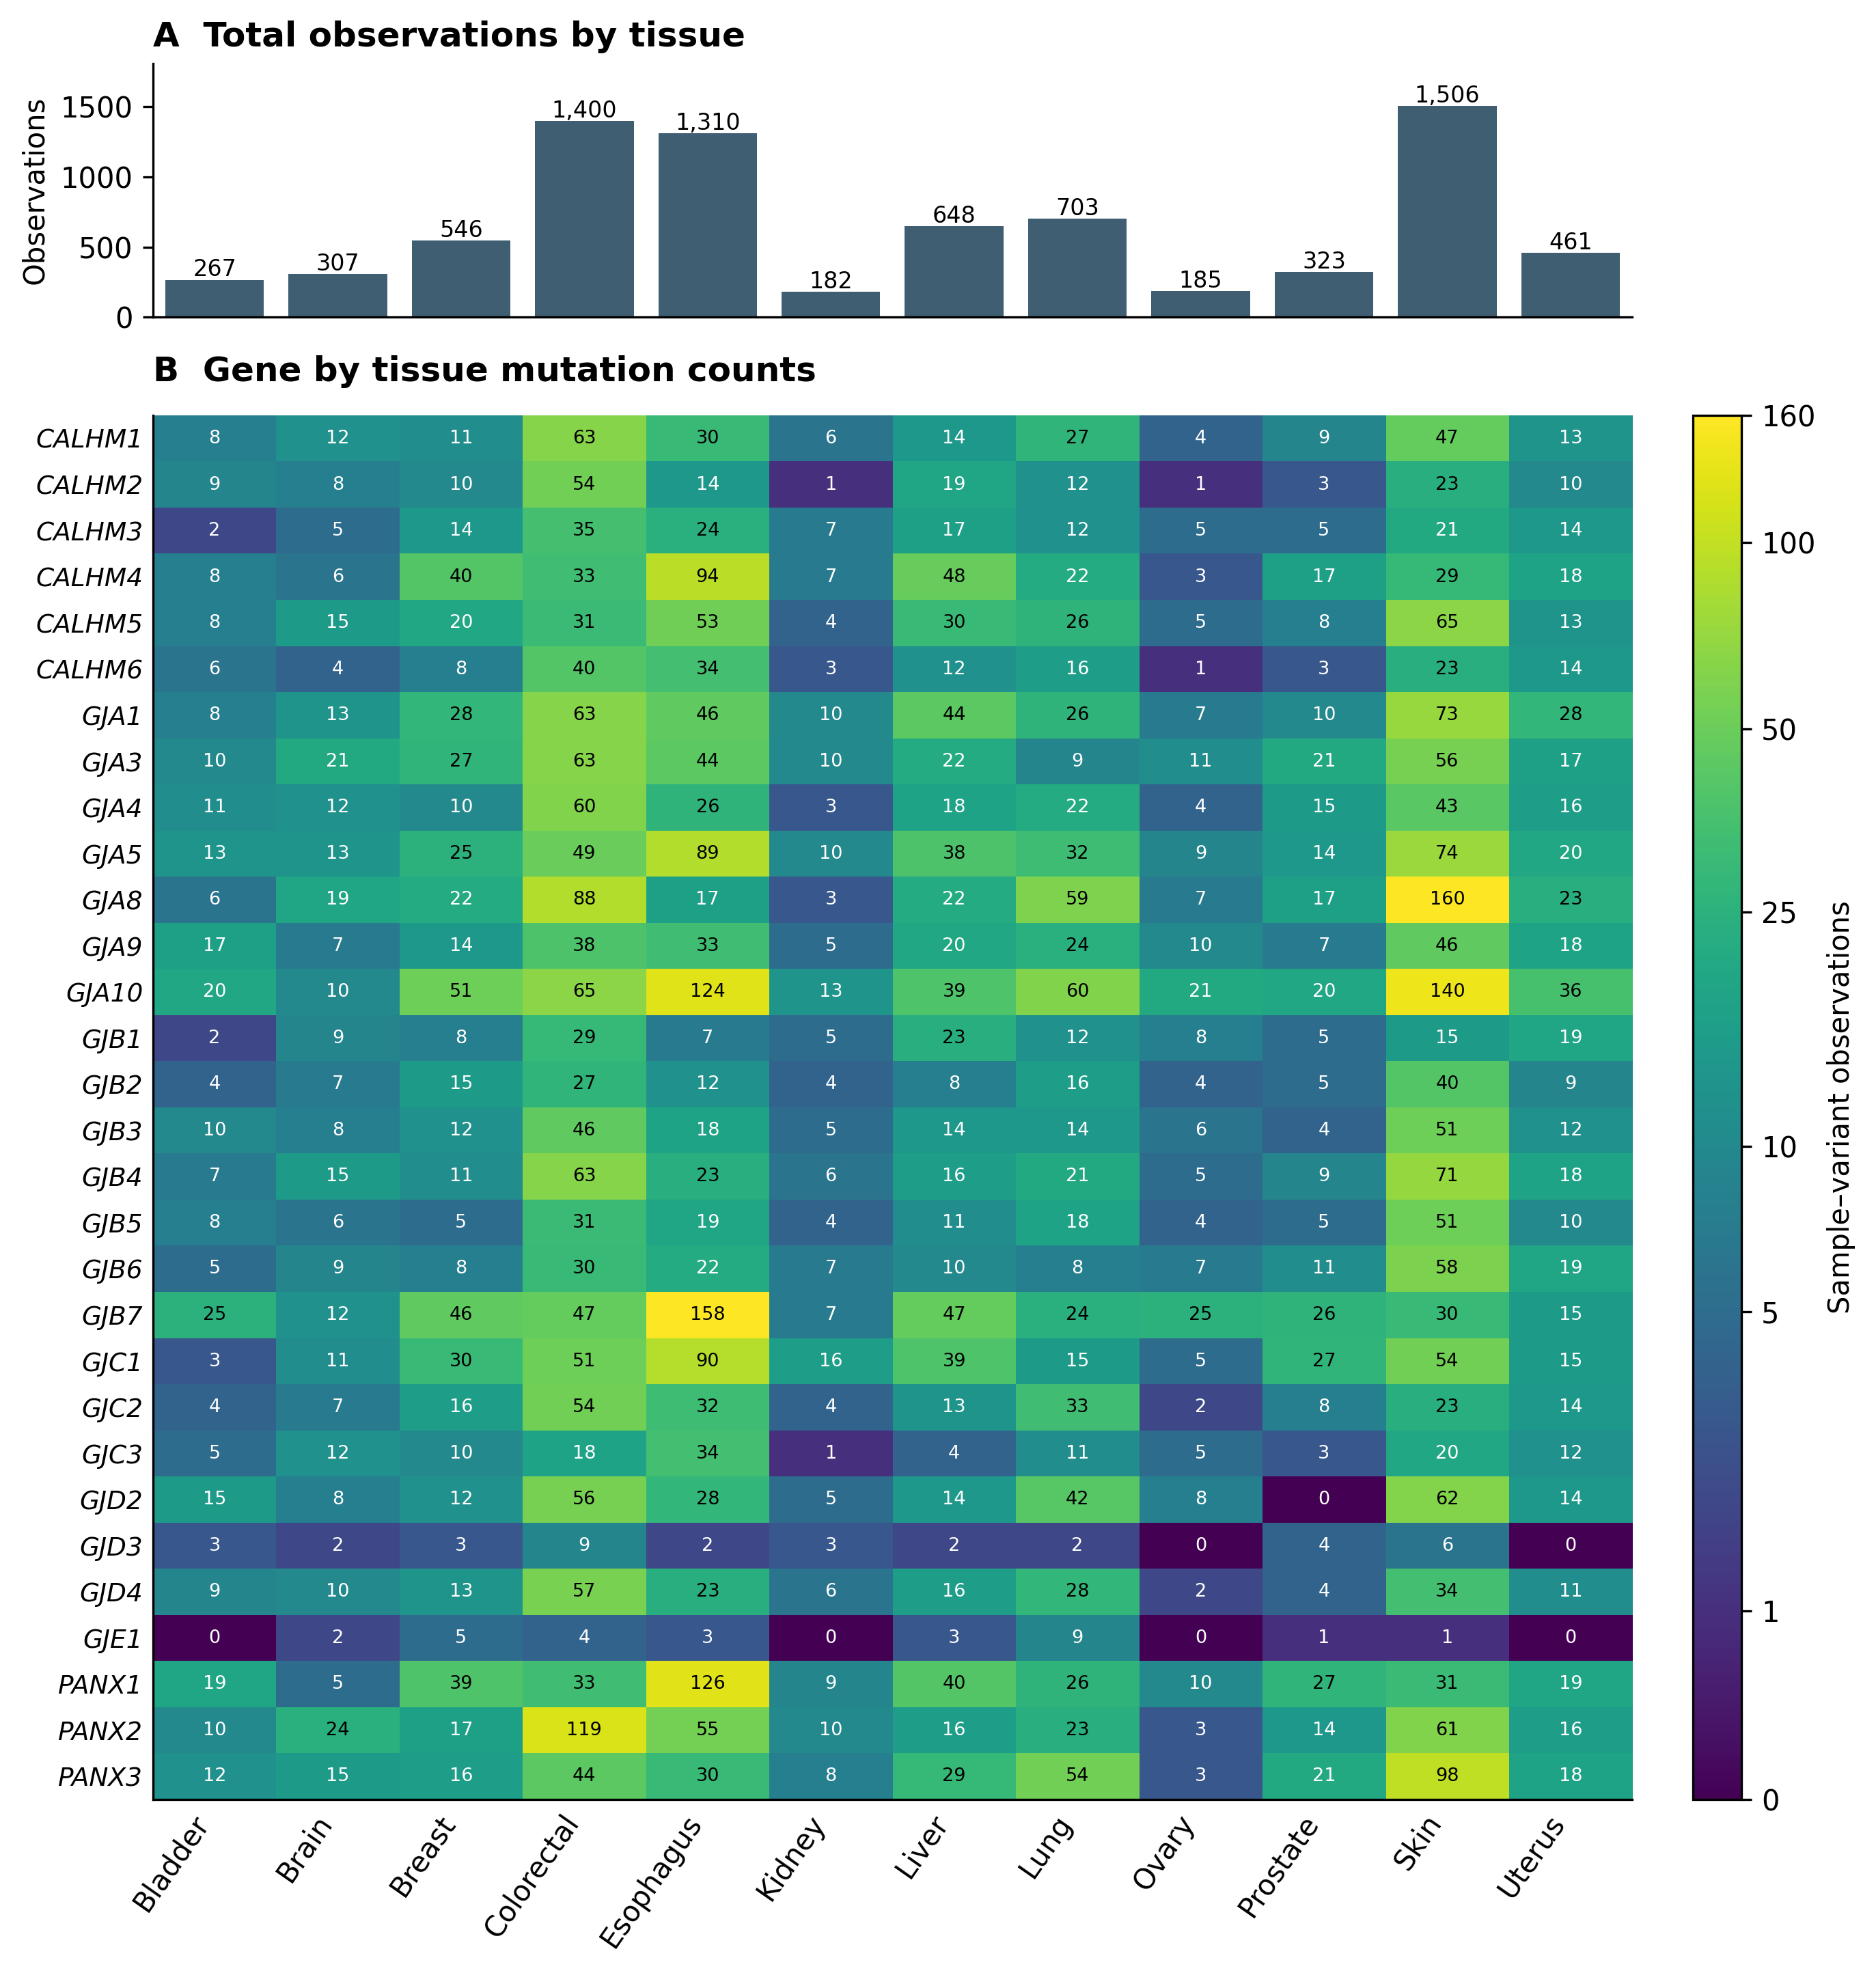

In [7]:
# Shared x positions align the tissue totals with heatmap columns.
fig=plt.figure(figsize=(10,11)); gs=fig.add_gridspec(2,2,height_ratios=[1.1,6],width_ratios=[20,0.65],hspace=.12,wspace=.08)
ax1=fig.add_subplot(gs[0,0]);ax2=fig.add_subplot(gs[1,0]);cax=fig.add_subplot(gs[1,1])
x=np.arange(len(TISSUES));bars=ax1.bar(x,totals.values,color="#3f5e72")
for b,value in zip(bars,totals):ax1.text(b.get_x()+b.get_width()/2,value+25,f"{value:,}",ha="center",fontsize=8)
ax1.set_ylim(0,totals.max()*1.20);ax1.set_xlim(-.5,11.5);ax1.set_xticks([]);ax1.set_ylabel("Observations")
ax1.set_title("A  Total observations by tissue",loc="left",fontsize=12,fontweight="bold")
v=matrix.to_numpy();norm=FuncNorm((np.log1p,np.expm1),vmin=0,vmax=v.max())
im=ax2.imshow(v,cmap="viridis",norm=norm,aspect="auto")
ax2.set_xticks(x,TISSUES,rotation=55,ha="right");ax2.set_yticks(range(30),GENES,fontstyle="italic",fontsize=9)
ax2.set_title("B  Gene by tissue mutation counts",loc="left",fontsize=12,fontweight="bold",pad=12)
for i in range(30):
    for j in range(12):
        value=int(v[i,j]);ax2.text(j,i,str(value),ha="center",va="center",fontsize=6.5,color="black" if norm(value)>.62 else "white")
cb=fig.colorbar(im,cax=cax); ticks=[0,1,5,10,25,50,100,160];cb.set_ticks(ticks);cb.set_ticklabels(ticks)
cb.set_label("Sample–variant observations")
ax2.tick_params(length=0);save_figure(fig,"S6")

## 7. Paired values and length-normalized COSMIC scatter (Fig S5)

The x-axis is the All SNV fraction. In recompute mode, `USE_RECOMPUTED_X=True` updates both correlation figures using the recalculated All SNV fractions.

COSMIC normalization is `1000 × observations / genomic_gene_span_bp`; the span includes introns/UTRs and is not coding length. Colours show the archived canonical protein length (amino acids). The OLS line inference uses a two-sided Spearman correlation across genes.

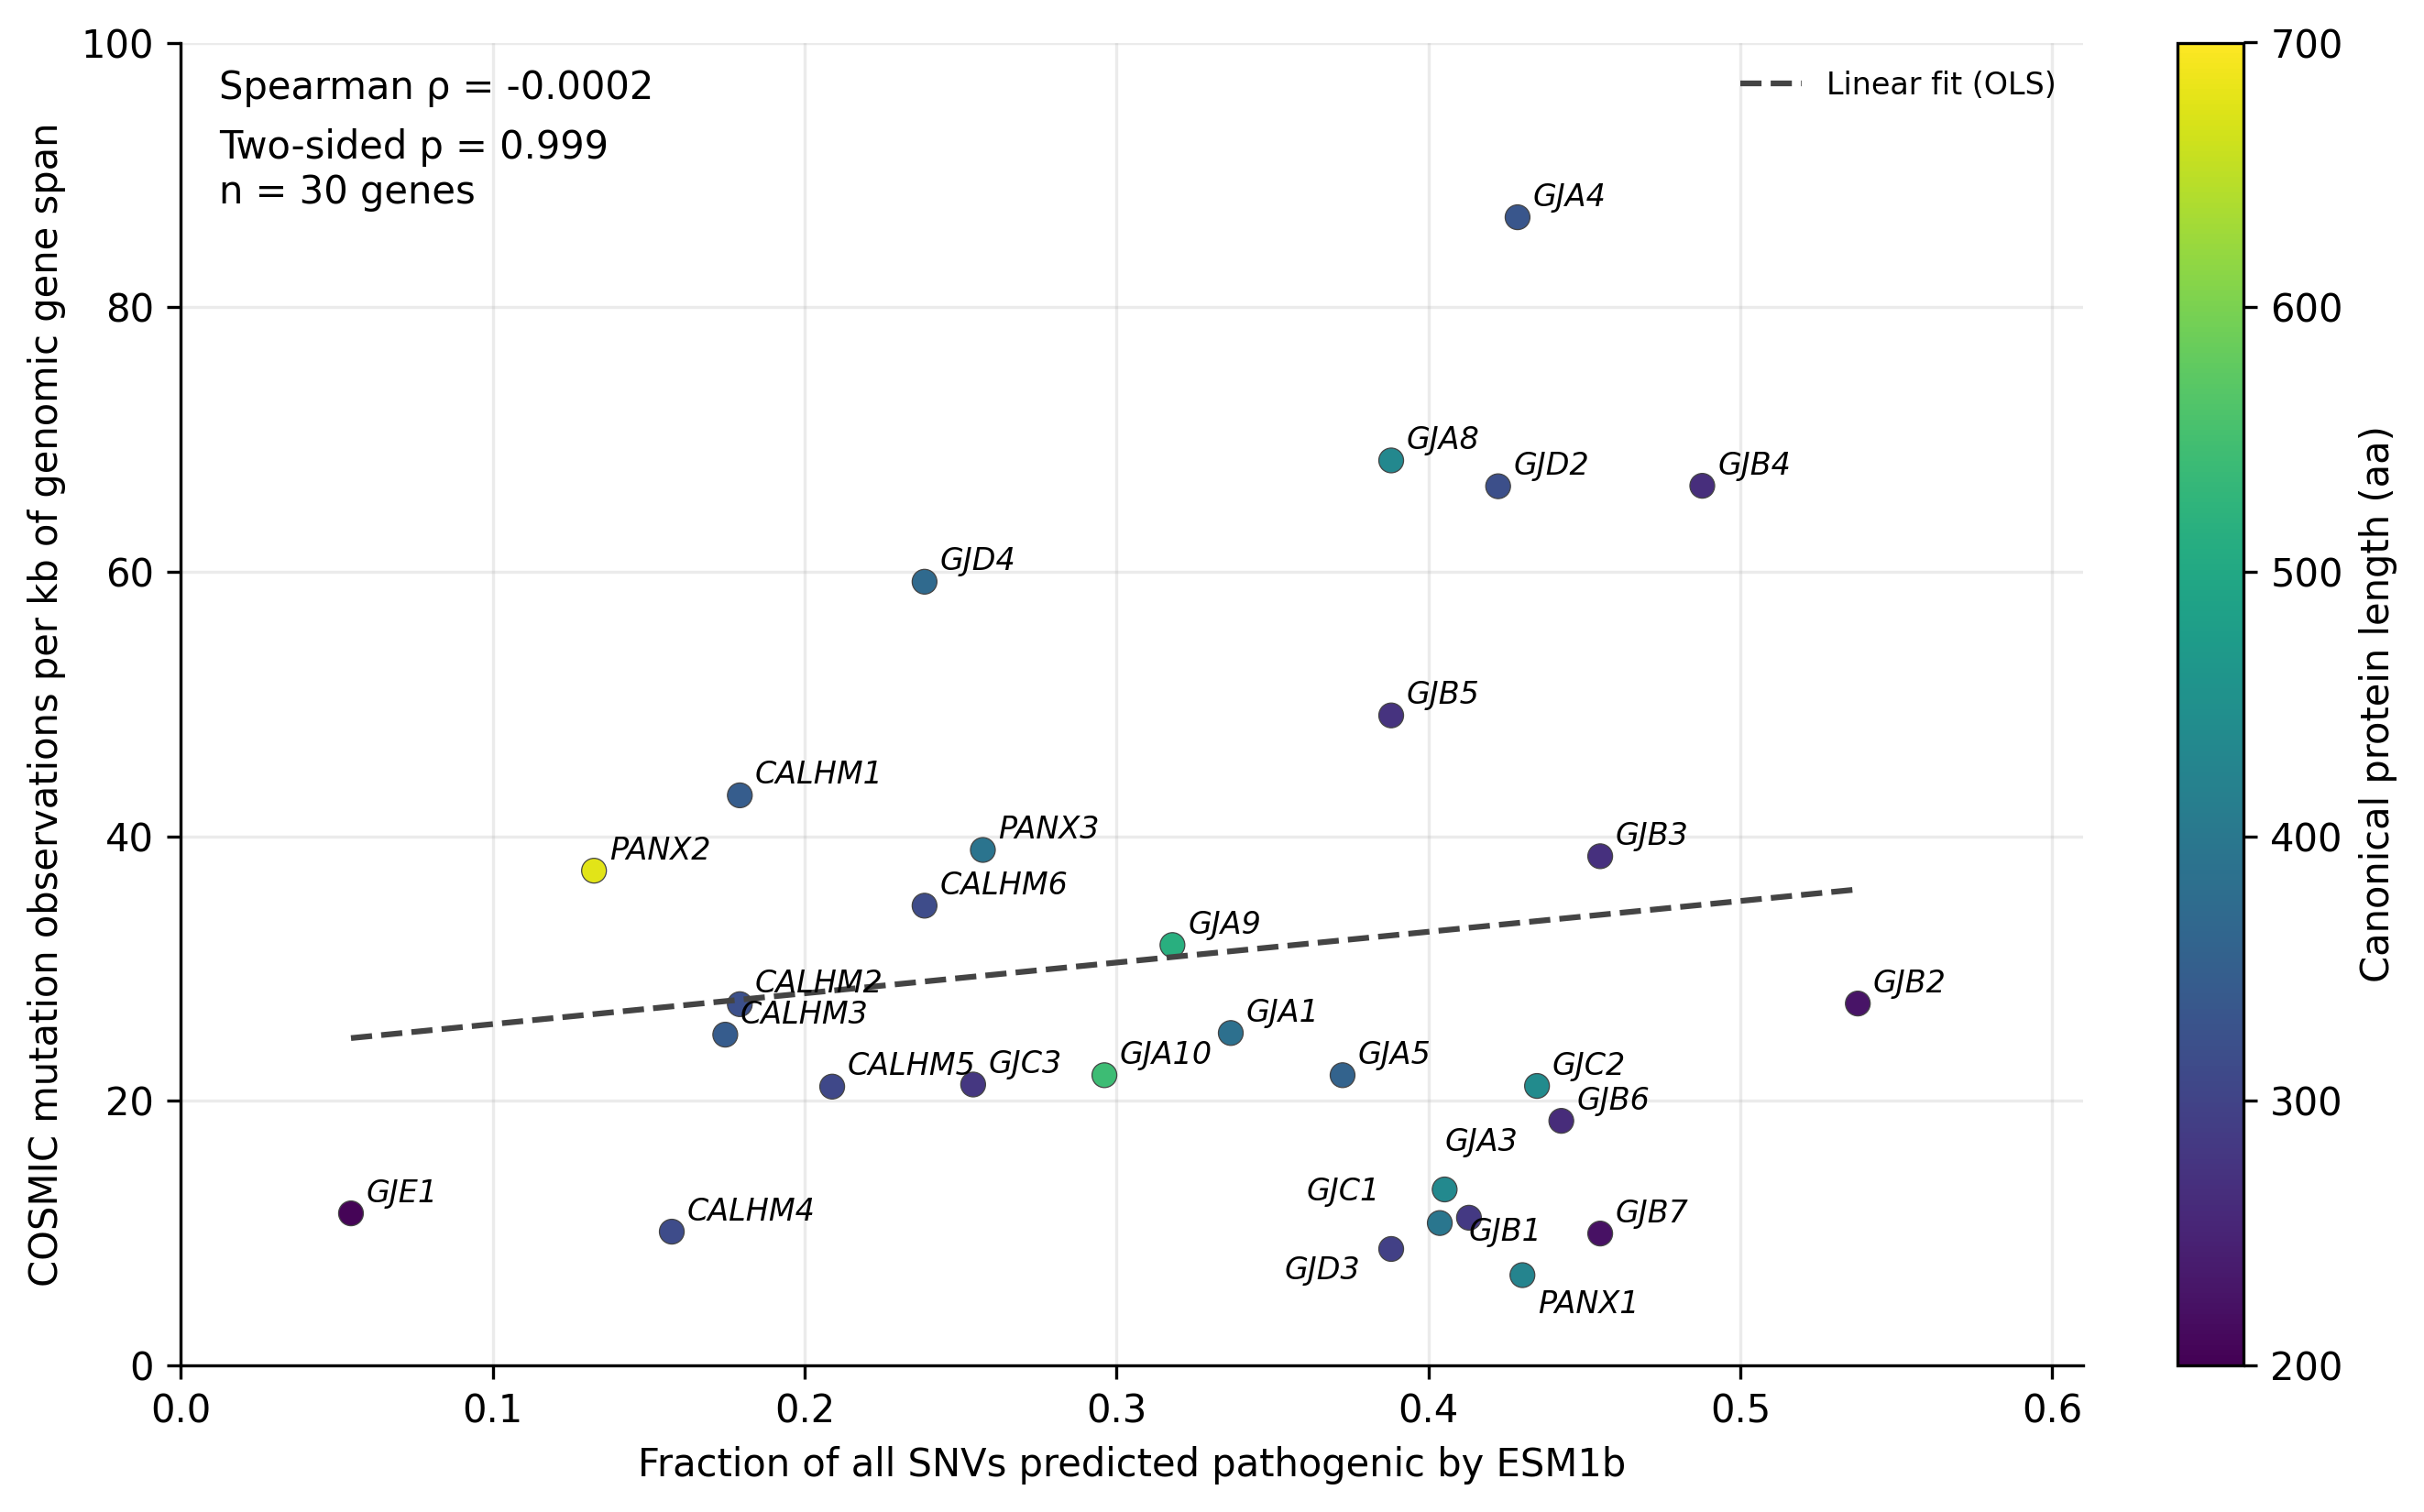

In [8]:
historical_x=pd.read_csv(DATA/"historical_correlation_x.tsv",sep="\t").set_index("gene").loc[GENES]
paired=manifest.join(historical_x)
paired["pathogenic_fraction"]=paired.All_SNV_pathogenic_fraction_approx
x_source="historical digitized Figure 5 All SNV fractions"
if MODE=="recompute" and USE_RECOMPUTED_X:
    paired["pathogenic_fraction"]=figure5[figure5.category.eq("All SNV")].set_index("gene").fraction
    x_source=f"recomputed ESM1b fractions; {COUNTING}"
paired["cosmic_observations"]=matrix.sum(axis=1)
paired["cosmic_per_genomic_kb"]=1000*paired.cosmic_observations/paired.gene_span_bp
results=[]

def scatter_panel(frame,y,label,name,include=None):
    include=pd.Series(True,index=frame.index) if include is None else include.reindex(frame.index)
    fit=frame.loc[include,["pathogenic_fraction",y]].dropna()
    rho,p=stats.spearmanr(fit.pathogenic_fraction,fit[y],alternative="two-sided")
    slope,intercept=np.polyfit(fit.pathogenic_fraction,fit[y],1)
    results.append(dict(figure=name,analysis="primary",n=len(fit),rho=rho,p_two_sided=p,x_source=x_source))
    fig,ax=plt.subplots(figsize=(9.4,5.6))
    keep=frame.loc[include];exclude=frame.loc[~include]
    sc=ax.scatter(keep.pathogenic_fraction,keep[y],c=keep.protein_length_aa,cmap="viridis",norm=Normalize(200,700),s=42,edgecolor="#444",linewidth=.3)
    if len(exclude):ax.scatter(exclude.pathogenic_fraction,exclude[y],marker="x",c="#999",s=60,label="GJE1: excluded from fit/test")
    xx=np.array([fit.pathogenic_fraction.min(),fit.pathogenic_fraction.max()]);ax.plot(xx,intercept+slope*xx,"--",color="#444",label="Linear fit (OLS)")
    for gene,r in frame.iterrows():
        offsets={"GJC1":(-35,6),"GJB1":(0,-6),"GJA3":(0,10),"GJD3":(-28,-8),"PANX1":(4,-10)} if name=="S5" else {"CALHM6":(-40,10),"PANX3":(4,-8)}
        ax.annotate(gene,(r.pathogenic_fraction,r[y]),xytext=offsets.get(gene,(4,3)),textcoords="offset points",fontsize=8,fontstyle="italic")
    ax.text(.02,.98,f"Spearman ρ = {rho:.4f}" if name=="S5" else f"Spearman ρ = {rho:.3f}",transform=ax.transAxes,va="top")
    ax.text(.02,.935,f"Two-sided p = {p:.3f}\nn = {len(fit)} genes",transform=ax.transAxes,va="top")
    ax.set_xlabel("Fraction of all SNVs predicted pathogenic by ESM1b");ax.set_ylabel(label)
    ax.set_xlim(0,.61);ax.set_ylim(0,100 if name=="S5" else max(1000,float(frame[y].max())*1.14));ax.grid(alpha=.25);ax.set_axisbelow(True);ax.legend(loc="upper right",frameon=False,fontsize=8)
    fig.colorbar(sc,ax=ax,pad=.04,label="Canonical protein length (aa)")
    fig.tight_layout();save_figure(fig,name)
    return rho,p
rho_s5,p_s5=scatter_panel(paired,"cosmic_per_genomic_kb","COSMIC mutation observations per kb of genomic gene span","S5")
if MODE=="snapshot" or not USE_RECOMPUTED_X:
    assert abs(rho_s5-(-.0002225))<.0001 and p_s5>.999

## 8. gnomAD variant counts from cached API responses (Fig S7)

The archived responses were retrieved 11 November 2026 from the gnomAD GraphQL API (`gnomad_r4`, GRCh38). For each selected canonical transcript, CDS intervals are read from its response, and distinct variants must be nucleotide substitutions inside CDS, have positive exome AC/AN, have no exome filters, and have transcript `major_consequence = missense_variant`. Each allele record counts once, regardless of carrier count or allele frequency. Exome/genome data are not pooled. This all-frequency count differs from rare-variant `mis.obs` used for constraint modelling.

GJE1 is displayed but excluded from the primary 29-gene fit/test because of the archived low-exome-coverage and missense-outlier flags. We also report the all-30-gene sensitivity and length-adjusted rank association. These tests are exploratory, with nominal p-values; no multiple-testing correction is claimed for this raw-count endpoint.

In [9]:
variant_rows=[]; gnomad_meta=[]
for gene in GENES:
    archive=json.loads((DATA/"api"/f"{gene}.json").read_text())
    t=archive["response"]["data"]["transcript"]
    assert t["transcript_id"]==manifest.loc[gene,"gnomad_transcript_id"]
    intervals=[(e["start"],e["stop"]) for e in t["exons"] if e["feature_type"]=="CDS"]
    cds_bp=sum(b-a+1 for a,b in intervals)
    ids=set();count=0
    for v in t["variants"]:
        if v["variant_id"] in ids:raise ValueError("Duplicate allele in gnomAD response")
        ids.add(v["variant_id"])
        ex=v["exome"];tc=v["transcript_consequence"]
        if tc: assert tc["transcript_id"]==t["transcript_id"]
        snv=len(v["ref"])==len(v["alt"])==1 and v["ref"] in "ACGT" and v["alt"] in "ACGT"
        coding=any(a<=v["pos"]<=b for a,b in intervals)
        passed=bool(ex and ex["ac"]>0 and ex["an"]>0 and not ex["filters"])
        keep=bool(snv and coding and passed and tc and tc["major_consequence"]=="missense_variant")
        if keep:
            count+=1;variant_rows.append(dict(gene=gene,variant_id=v["variant_id"],AC=ex["ac"],AN=ex["an"]))
    gnomad_meta.append(dict(gene=gene,missense_count=count,gnomad_cds_bp=cds_bp))
gnomad=pd.DataFrame(gnomad_meta).set_index("gene")
archived=pd.read_csv(DATA/"gnomAD_30genes_summary.tsv",sep="\t").set_index("gene").loc[GENES]
assert np.array_equal(gnomad.loc[GENES,"missense_count"],archived.exome_missense_SNVs)
assert np.array_equal(gnomad.loc[GENES,"gnomad_cds_bp"],archived.gnomad_cds_bp)
paired=paired.join(gnomad)
paired["primary_include"]=archived.primary_include.astype(bool)
assert paired.index[~paired.primary_include].tolist()==["GJE1"]
paired["missense_per_cds_kb"]=1000*paired.missense_count/paired.gnomad_cds_bp
pd.DataFrame(variant_rows).to_csv(OUT/"S7_counted_exome_missense_alleles.tsv.gz",sep="\t",index=False)
rho_s7,p_s7=scatter_panel(paired,"missense_count","Number of distinct PASS missense SNVs (gnomAD exomes)","S7",paired.primary_include)
if MODE=="snapshot" or not USE_RECOMPUTED_X:
    assert abs(rho_s7-(-.394))<.001 and abs(p_s7-.0345)<.0001
for title,sub,col in [("all_30",paired,"missense_count"),("length_normalized_29",paired[paired.primary_include],"missense_per_cds_kb")]:
    rho,p=stats.spearmanr(sub.pathogenic_fraction,sub[col],alternative="two-sided")
    results.append(dict(figure="S7",analysis=title,n=len(sub),rho=rho,p_two_sided=p,x_source=x_source))
# Partial rank association: residualize ranked x/y on ranked protein length.
sub=paired[paired.primary_include]
x=stats.rankdata(sub.pathogenic_fraction); y=stats.rankdata(sub.missense_count); z=stats.rankdata(sub.protein_length_aa)
Z=np.column_stack([np.ones(len(z)),z]);rx=x-Z@np.linalg.lstsq(Z,x,rcond=None)[0];ry=y-Z@np.linalg.lstsq(Z,y,rcond=None)[0]
r=np.corrcoef(rx,ry)[0,1];df=len(sub)-3;tvalue=r*np.sqrt(df/(1-r*r));p=2*stats.t.sf(abs(tvalue),df)
results.append(dict(figure="S7",analysis="partial_rank_protein_length_29_approximate_t_test",n=len(sub),rho=r,p_two_sided=p,x_source=x_source))
paired.to_csv(OUT/"integrated_gene_values.tsv",sep="\t")
results=pd.DataFrame(results);results.to_csv(OUT/"correlation_statistics.tsv",sep="\t",index=False)
display(results)

,figure,analysis,n,rho,p_two_sided,x_source
0,S5,primary,30,-0.000223,0.999068,historical digitized Figure 5 All SNV fractions
1,S7,primary,29,-0.393984,0.034453,historical digitized Figure 5 All SNV fractions
2,S7,all_30,30,-0.267869,0.152389,historical digitized Figure 5 All SNV fractions
3,S7,length_normalized_29,29,-0.069518,0.720094,historical digitized Figure 5 All SNV fractions
4,S7,partial_rank_protein_length_29_approximate_t_test,29,-0.185390,0.344920,historical digitized Figure 5 All SNV fractions


## References and source audit

* Brandes N, Goldman G, Wang CH, Ye CJ, Ntranos V. Genome-wide prediction of disease variant effects with a deep protein language model. *Nature Genetics* (2023). https://doi.org/10.1038/s41588-023-01465-0
* Upstream ESM1b variant-scoring implementation and CSV specification: https://github.com/ntranoslab/esm-variants — `esm_score_missense_mutations.py` (reviewed for this workflow).
* COSMIC source methods: the archived CancerLetters `COSMIC_gnomAD_integrated_report.docx`; COSMIC v104 target export with sample/classification joins. Raw joined annotations and original join audit accompany this notebook.
* gnomAD variant API: https://gnomad.broadinstitute.org/api ; cached responses retain original query, date and dataset. Constraint release source: https://storage.googleapis.com/gcp-public-data--gnomad/release/4.1.2/constraint/gnomad.v4.1.2.constraint_metrics.tsv.bgz (only target records retained).
* Original notebooks are retained in `provenance/`. The latest `snvs_ros_suppMat.ipynb` supersedes the earlier incomplete ROS blocks. Its undefined plotting variable `del_` is replaced here by a tidy fraction table; file paths are portable and shell `os.system()` calls are replaced with checked subprocess calls.
